# Task 3 — Species reverse the pooled bill relationship

Completed Week 1 assignment. Every chart is followed by its design justification and interpretation.

**Run:** Python 3 with `pandas`, `numpy`, `matplotlib`, `seaborn`, and `IPython`. Use **Restart Kernel and Run All**. The original CSV is embedded, so no network or extra data files are needed.

**Data source:** [penguins.csv](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv), downloaded 30 September 2026 using the assignment script's source URL. These are historical teaching datasets, not current-world estimates.

**Chart policy:** finding-led titles, no dual y-axes, zero-based bars, meaningful colour and selective labels. The deliberately messy Task 2 chart is the required counterexample.

In [1]:
import base64, zlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
def finish(fig, note):
    fig.text(0.01, 0.012, note, fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.065, 1, 0.96))
    plt.show()

# Compressed CSV snapshot from the source linked above.
# Replace df with pd.read_csv("data/penguins.csv") to use your local assignment file.
CSV_B64 = (
    'eJyFW01zHbkNvOe3TKmG3+Rxk2xySW65u5z1i1dVsqTS82H334dEg5x5QwLag6pcpkEQaDQaGO39/fbb8+2+Pd9fvr5+2/77/PLy'
    '5eX2+v3n719+/MAfv93e8af/vTy/v98+zn//9u3PLz++3u9fvm/32x9/+eXb7eX5tv3n7eP77eN+e91ceTKbyU+p/jCbS2Hf/v3L'
    'v35dHgybSU++Hoyby/u+/ePX9VG/P7l6ajMlbM4G+WD7b3FTbN6UZqO4zXnFgGun7P4U69G9/kPZ+/xUmvcZz4w2aDZtuz6S/z6m'
    'INn0CJ1hP+vBRSxs88+Sf77FYmGH3EpkrEbW7dqhFtj60rQ85E0zkprr2dbQKzmqAYmbNeSZQTrFV9LB9sq8eS8fjO1ehDjAQ+Xy'
    'lmEARMuvtxV0NX7tdNrqScXLBkz64WsMlfx6ek7FcvHV/sXiX5/vv73dONq5RTtVc356y3Eu9epp+BOshQY+glUuq9Lp5zIdISDU'
    'wJSwtpaBBIs7r5k77mxQaRfnpNzpqXgy/aggDus76ykqfrY2A+uIR2FrqQLQTKl9sAfv9vmlf/+4ff3BjENkkPKKSPhYGlFrx8ou'
    '20JWM2psZav6VbpfXrQVG8wS0DsjbVxoe9nEWpjrF7ZU2h3ktQ5CrQB6XUCkghyEyJzZ+E16X/Wq0TIhrKL/ypfjfYHoOy9TOCKV'
    'ueBaGKRIddcrrxkp5kSjhWo8zgTT39eQUFAYu/w6ujCDba/VyNchJ3hdZeTlZQOdqWy2nIj9eBchveVt5q+ROXcw7ISAXjEFrJkQ'
    'pKDUqenIrDTspKpXHeu2qL81Yq1R2gW/PGJgqOJtEf0yIN6IPpIEv6j5MhBmDF+4KKOhSswWQQuRoG6zZK2XhCGmn5TNwZNnaMmM'
    'ZZBNA1VwRenDnQm2ohIzymVLg5UzAJrhWpXfWa1FqC0r94yAmFkmLcWW6fxQUWbkfkstLXbhtWs93IBzPAsIWaM56sos5TT5UNB1'
    'PROn7CUXlyVqWQDv5GUAnxUojWu1Prw8MJjLrsucygCZCbBhxoo20XYixcl8Ip3wmi50lLdTtiMXsP52O7Le/Nx1LcjSo+j6stos'
    'LEUbq1954ar2qejXQuUh9KYjyc3abZC3407fYjlDfbQBmhwc2OGqe0YndKBKyvWVkMahrnlaUGYGH73enUSgIHlA8NzBFkXAx4i0'
    'mnSwsiToLFM5cg9zx2BLg2LCSuY+9lUMKFMFjzDYPqAkVWFxndl90cdGGExvKssaG7Zcr6/ql1v75ZqtyPJw0cjYlhs6q3Hylfmm'
    '/loDnybpN1i0iTq7V4ymi8B4mBtYc+9JsENTCMvDiT1mxV1rwhbJp86ZrGwFne/yQZgFPVOeVIZwFWIFSQ5BaqQ3Iu7Muimto5WR'
    'wkAdxGUx7qGNqqhpM+u/h0hQAprKEGcZKG8Uf/XNCr4V3JlAN7JOsoi/A1Z3eauQu4RYovWhExCDBc6VbJHYIoF3Zj68rg8Gkzkr'
    'WuRat6j1WTQ9eEnLnIzcyRO8py1JczR+shNgxRlAf1l7d7VIQqXJTlWjYIVEkdT6H4/eLHbtBOoHL0PP94J9zxqFGbhZVH3EuqmK'
    '0P0TH89DgLoJceinlhA+5Wbw+hAxTmlvPDMBjd6n5WCVj/1UwvQld64hsYTZMoCqAiI3E8zoEbSBMzTtuLL2KzG9fNIFUw+sm/n4'
    'dB3n08m2gLdRQEK0SJaR3Gw7ixkbwxbKm1qlNNC6ri+tNj/3XVaYd6mntcbozEIQsAkcyzgvpMb1deF6Czhcz6cl63WKO1tipSuq'
    'BdMRandzqqC//f78ev/58fW9n4tP5y5/Avz1ZNh7f4gnlE6nzBB+7QUjrtO9AbwG6nfhKI7Joj04NZ1yvrBoe4gzJKdg0ccxkV5W'
    'bevX5M4ZSXxN7NNUwDSl2it0Mp/2BwsPB1zcw5iwsJhOyn70xcli6nL1cVs9R7uraHOa1RexHkTe9nRJzh5aNskGzWLYqb8jzk5E'
    'Vz591lBe4eOxp3ncDU0nucTtZdMxnbPYT/DKMSp352NkNiDF9TmHkTVOO6dFbOIxCR6D2eLVg7PDw1CyyvJ19l9nrvEa9RKvvBi0'
    'gHOad/40qqoYxCRAk1wQMbiPpcxlSz/Z8+iKGRgU0UXfX7CCp6FOq2PMrTT1GNEeTyH4tnZ8L5lrE/dmaFsFCR5qgnWWy4qHFjqd'
    '9JOWk7HYqv9AywnWVTTJhtO3qfnNvG015yX/4l7bd6QJXULGfunbmnia5BaMFKAL4iddDMxVcDKqzJVPHdQrdWLOe2itTpgJjVVQ'
    'GLhzMwqt+OIyvpG2XqK8xPNE6YEvp/RamjYKvVjJHkas/sla4cKAUZFalNP6iQVnus8rj78QsRoQswI1EMfwonYA15Gt+Rj2fjMm'
    'MbECwsHWXlc25qlXyx71asldshe1WnwffkvQqypgS93ekjR16Pp3EXqz3gNi76NO0SGoqgJeEpmzxzqxTjqw/c/b68+3t7FnICXn'
    '6OOjASstzzXt2rab1u1bGKrrYouua2Mn+XbSDLOtQDdm2RbxtCceDLX/CKcopY7Z0gfpRmhl/GaCAZtL0UjNt/bpptRKEW51De+O'
    '+nqB4pGs5WbN4w1DJ1xOEZ866jT8jXVtrWAtaU2s6BNsBcTjU1v5iIermlC0lvupHftzwbMWj0C3JtmaPWXKyK/EEqaiw5otOjHv'
    'ltHRMiDnMyOfNWrW1g689gy14inrCiLpa8JA5K5kPfRzTkcHRS2zPSlqQIf5/FbDLyWsCW/w8M0Riog95rprmIWVKPiUj3jxd3Ol'
    'zuupqkRFxCZEwSFDVowCIdEi30mMwpGjysphFxkIH/qIzaIU+QJbGf7LiKVaiv2dElPZdiMqs6KiiNZ8n5LAQIJvvtmK/E1E8Sxx'
    'XdZzEvqxaXZ8ysmeUczqnbUdKzXi+it3KDTFVgAKk1iVAetYQoaEH4e4FuIeXxRkhH5O47LzrUrf8ahKB/40yq32VOMym0VGN80a'
    'Sj4D99eGNMka14DnLqy81FAOLPOKwmX+0+hyn2t+SfXkWg2785c8JVOBbYkdePB/VpVGqyawi9e6JqE2w5rc57jrFOpNSvxTR5rX'
    '4u9H13RG5towmM+ozFegcLOu0PgF/tAHsx3+zQ9rK/9kMf6BvapZkr3C9NJy6bQOkB64QIo9ZTIi9hIuMuqNT0ldkFGdoVe0fPvD'
    'M0VjgBdb3KV4pRGv1r/kjmkwZ6KXROmVxCqOWUWJGU9wHvEvep8LmKpPv+p88c2CGTm2XszmUJYW37MVbVBQl1JnYpbNbEupcp7j'
    'ra19LoqY9R37Wc+B6xWX5SpHRuFZlqarYPFNm7Ah4x9817wSuy+m9kTcn+W+FA7tqUWsV7lB/CXuYbXI04TYlxB/YjIb5ampoIIz'
    '6qn0rxBTzRXGj9Ui2ycYj52DjFrTfxeA+pykp3LPQdHeiZ29jrIEBoKC9kX0v/TuW20F0VbvS8RA9QHLCTN21S/ZMZjLWZXJbO2O'
    'DBXZGk2/Hr0yKPnp88gu2+pqy2KqlaebAoQVdCWJydxhzSnTL/aDY5shvZN7pYH2cWKNk97q/K9VUp+QCdVzvHLvu1Zm/gTm54os'
    'Eurpf5RZQQVDW9CL2fdirrJbEOdoLZ6pWWmh5WmsLdyJtv4P517v/A=='
)
df = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(CSV_B64))))
assert len(df) == 344
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("missing rows").to_frame())

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


,missing rows
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


## Missing-data audit and decision
Keep unknown-sex penguins in charts that do not use sex. Exclude only rows missing the measurements needed by each chart; do not impute invented values.

In [2]:
measurements = ['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
print('Rows missing all four measurements:')
display(df.loc[df[measurements].isna().all(axis=1)])
print('Rows with missing sex:')
display(df.loc[df.sex.isna()])
mass = df.dropna(subset=['body_mass_g']).copy()
bills = df.dropna(subset=['bill_length_mm','bill_depth_mm']).copy()
sex_mass = df.dropna(subset=['body_mass_g','sex']).copy()
sex_mass['sex'] = sex_mass.sex.str.lower()
assert len(mass)==342 and len(bills)==342 and len(sex_mass)==333
print('Mass / bill charts retain 342; species-sex chart retains 333. Missing categories overlap.')
species_order = ['Adelie','Chinstrap','Gentoo']
palette = dict(zip(species_order, [BLUE,ORANGE,GREEN]))

Rows missing all four measurements:
Rows with missing sex:
Mass / bill charts retain 342; species-sex chart retains 333. Missing categories overlap.


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


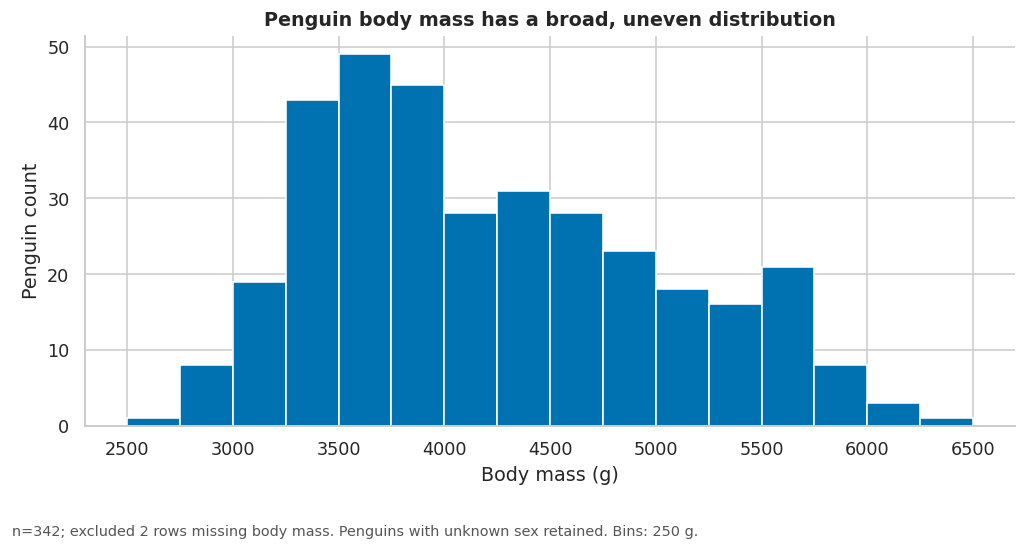

In [3]:
bins = np.arange(2500, 6601, 250)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(mass.body_mass_g, bins=bins, color=BLUE, edgecolor='white')
ax.set(title='Penguin body mass has a broad, uneven distribution',
       xlabel='Body mass (g)', ylabel='Penguin count', ylim=(0,None))
finish(fig, 'n=342; excluded 2 rows missing body mass. Penguins with unknown sex retained. Bins: 250 g.')

**Why a histogram:** Body mass is one continuous variable; a histogram exposes the shape rather than reducing it to a mean. The sample has several local humps and a heavier shoulder, rather than a clean single symmetric mound. Apparent peak counts depend on bin width, so I would not infer an exact number of populations from this pooled histogram alone.

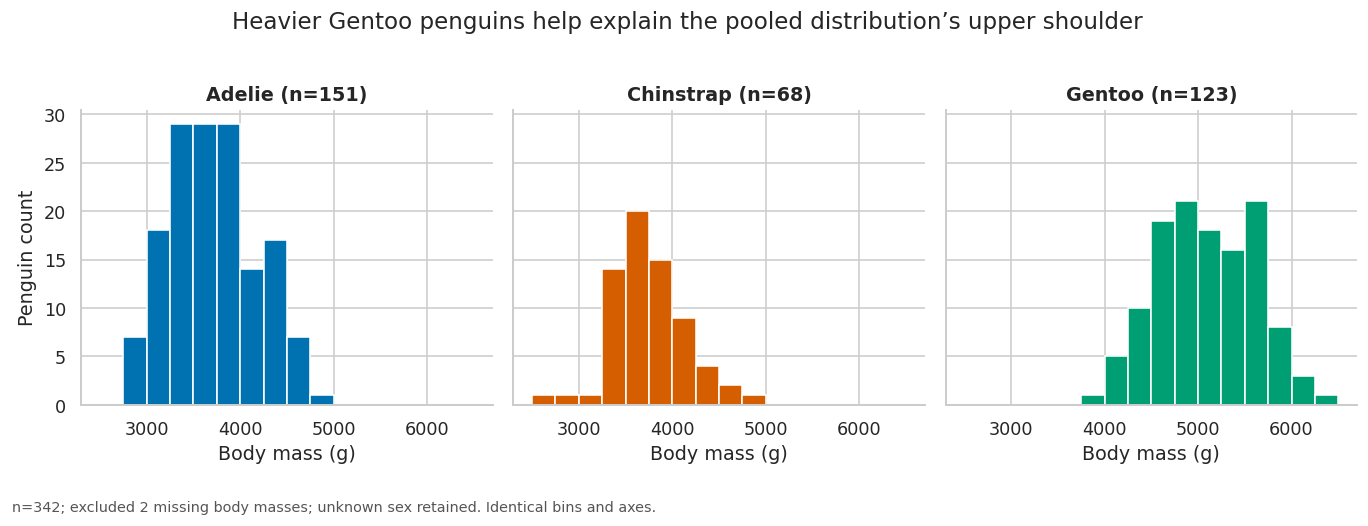

In [4]:
fig, axes = plt.subplots(1,3, figsize=(12,4.5), sharex=True, sharey=True)
for ax, species in zip(axes, species_order):
    g = mass[mass.species.eq(species)]
    ax.hist(g.body_mass_g, bins=bins, color=palette[species], edgecolor='white')
    ax.set_title(f'{species} (n={len(g)})')
    ax.set_xlabel('Body mass (g)'); ax.set_ylim(bottom=0)
axes[0].set_ylabel('Penguin count')
fig.suptitle('Heavier Gentoo penguins help explain the pooled distribution’s upper shoulder')
finish(fig, 'n=342; excluded 2 missing body masses; unknown sex retained. Identical bins and axes.')

**Why faceted histograms:** Identical bins and scales compare distributions directly without overlapping fills. Colour consistently denotes species. Gentoo penguins tend to be heavier; Adelie and Chinstrap overlap at lower masses. Mixing species helps explain the pooled shape, though within-species sex differences and binning can also create smaller humps. Counts reflect different species sample sizes; they are not population prevalence estimates.

,Pearson r
Adelie,0.391
Chinstrap,0.654
Gentoo,0.643
All pooled,-0.235


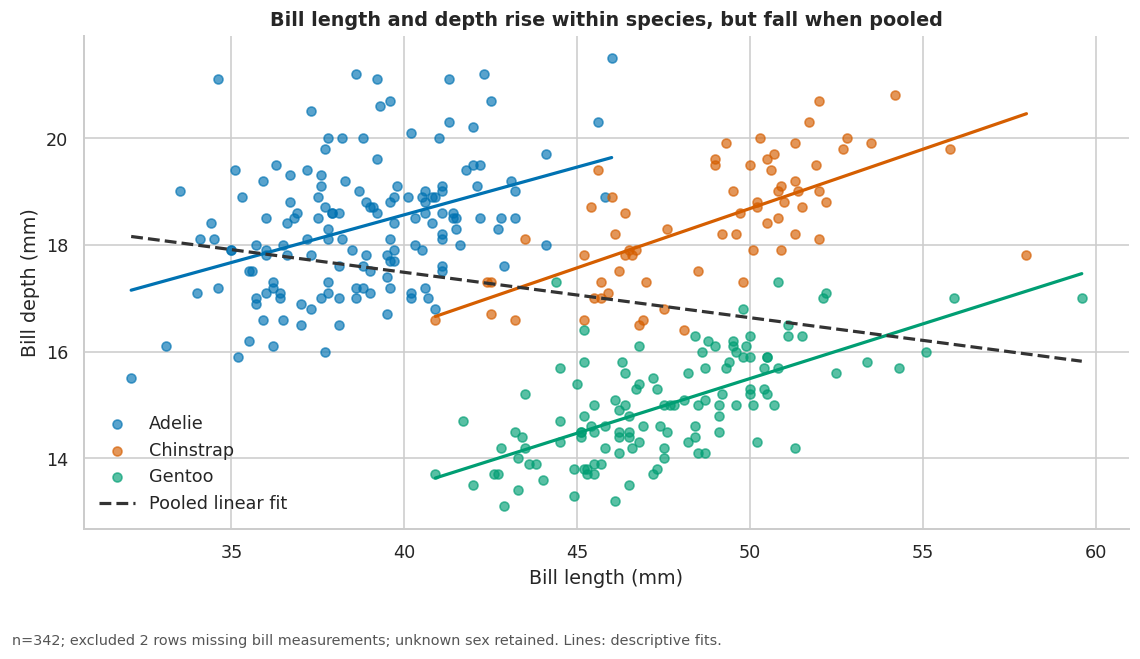

In [5]:
corr = pd.Series({s: g.bill_length_mm.corr(g.bill_depth_mm)
                  for s,g in bills.groupby('species')}, name='Pearson r')
corr.loc['All pooled'] = bills.bill_length_mm.corr(bills.bill_depth_mm)
display(corr.to_frame().round(3))
fig, ax = plt.subplots(figsize=(10,6))
for species in species_order:
    g = bills[bills.species.eq(species)]
    ax.scatter(g.bill_length_mm,g.bill_depth_mm, s=32,alpha=.65,
               color=palette[species],label=species)
    slope,intercept = np.polyfit(g.bill_length_mm,g.bill_depth_mm,1)
    x = np.linspace(g.bill_length_mm.min(),g.bill_length_mm.max(),100)
    ax.plot(x,slope*x+intercept,color=palette[species],lw=2)
slope,intercept = np.polyfit(bills.bill_length_mm,bills.bill_depth_mm,1)
x = np.linspace(bills.bill_length_mm.min(),bills.bill_length_mm.max(),100)
ax.plot(x,slope*x+intercept,color='#333333',ls='--',lw=2,label='Pooled linear fit')
ax.set(title='Bill length and depth rise within species, but fall when pooled',
       xlabel='Bill length (mm)',ylabel='Bill depth (mm)')
ax.legend(frameon=False)
finish(fig, 'n=342; excluded 2 rows missing bill measurements; unknown sex retained. Lines: descriptive fits.')

**Why a grouped scatter plot:** Points retain the paired measurements and species colour separates three biological groups. Separate fitted lines make the within-species slopes visible; the dashed pooled fit shows the reversal.

**What is happening:** Pooled r is about **−0.235**, while species correlations are positive: Adelie **0.391**, Chinstrap **0.654**, Gentoo **0.643**. Gentoo generally have longer but shallower bills than the other groups, pulling the pooled trend down. Within a species, longer bills tend to be deeper. Differences **between** group centres dominate the pooled relationship.

This reversal is **Simpson’s paradox**: aggregation can reverse an association present in subgroups. Species is the relevant grouping variable here. These correlations describe association, not proof that bill length causes depth. Reference: [Kievit et al. (2013), *Simpson’s paradox in psychological science: a practical guide*](https://doi.org/10.3389/fpsyg.2013.00513).

mean           size     
sex        female    male female male
species                              
Adelie     3368.8  4043.5     73   73
Chinstrap  3527.2  3939.0     34   34
Gentoo     4679.7  5484.8     58   61

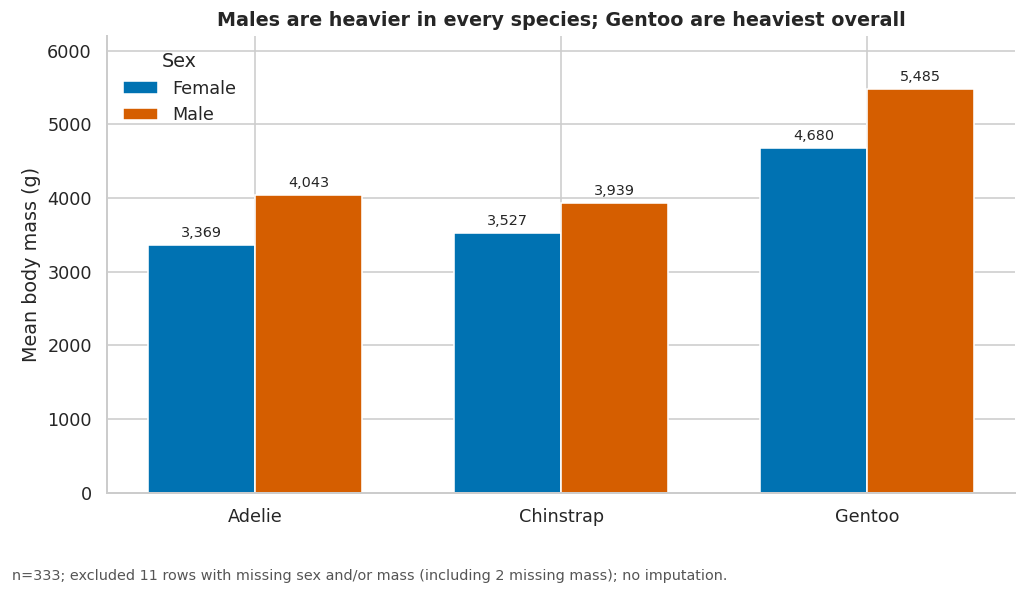

In [6]:
means = sex_mass.groupby(['species','sex']).body_mass_g.agg(['mean','size']).unstack('sex')
display(means.round(1))
fig, ax = plt.subplots(figsize=(9,5.4))
x=np.arange(3);width=.35
sex_colors={'female':BLUE,'male':ORANGE}
for i,sex in enumerate(['female','male']):
    heights=[means.loc[s,('mean',sex)] for s in species_order]
    bars=ax.bar(x+(i-.5)*width, heights,width,color=sex_colors[sex],label=sex.title())
    ax.bar_label(bars,labels=[f'{v:,.0f}' for v in heights],padding=3,fontsize=9)
ax.set_xticks(x,species_order)
ax.set(title='Males are heavier in every species; Gentoo are heaviest overall',
       ylabel='Mean body mass (g)',ylim=(0,6200))
ax.legend(title='Sex',frameon=False)
finish(fig, 'n=333; excluded 11 rows with missing sex and/or mass (including 2 missing mass); no imputation.')

**Why grouped bars:** The question asks for means across two categorical variables; adjacent zero-based bars enable female–male comparisons inside each species. Colour now denotes sex, as stated in the legend, because species is already on the x-axis. Labels give the six averages without labelling individual penguins. Males have larger mean mass in all three species, and Gentoo have the largest means. These are complete-case sample averages, not uncertainty estimates or full distributions; excluding unknown-sex rows could bias them if missingness is systematic.